In [70]:
from plot_eval_logs.parse_eval_logs import EvalRun
from pathlib import Path
from typing import TypedDict
import numpy as np
import matplotlib.pyplot as plt



class EvalRunsDict(TypedDict):
    harm: EvalRun
    benign: EvalRun

def calculate_nss(padding2evals: dict[int, EvalRunsDict], score_threshold:float| tuple[float,float]):# -> tuple[dict[str, dict[Any, Any]], dict[Any, Any]]:
    def filter_samples_metrics(eval_run: EvalRun, idxs: set):
        filtered_samples_metrics = []
        for sample_metrics in eval_run.metrics_per_sample:
            if sample_metrics["id"] in idxs: 
                filtered_samples_metrics.append(sample_metrics)
        return filtered_samples_metrics


    # calculate idxs to filter examples
    no_pad_benign = padding2evals[0]["benign"]
    rel_scores_idxs = set()
    for sample in no_pad_benign.metrics_per_sample:
        sample_score = sample["score_obj"].value["score"] 
        
        if isinstance(score_threshold, float) and sample_score >= score_threshold:
            rel_scores_idxs.add(sample["id"])
        elif isinstance(score_threshold, tuple) and score_threshold[0] <= sample_score <= score_threshold[1]:
            rel_scores_idxs.add(sample["id"])
    print(f"{score_threshold=} remains num_samples={len(rel_scores_idxs)}")

    
    filtered_scores = {"harm": {}, "benign": {}}
    filtered_refusal_rate = {}
    for pad_len, eval_runs_dict in padding2evals.items():
        benign_filtered = filter_samples_metrics(eval_runs_dict["benign"], rel_scores_idxs)
        filtered_scores["benign"][pad_len] = np.mean([s["score_obj"].value["score"] for s in benign_filtered]).item()
    
        harm_filtered = filter_samples_metrics(eval_runs_dict["harm"], rel_scores_idxs)
        filtered_refusal_rate[pad_len] = np.mean([s["score_obj"].value["refusal"] for s in harm_filtered]).item()
        filtered_scores["harm"][pad_len] = np.mean([s["score_obj"].value["score"] for s in harm_filtered]).item()

    return filtered_scores, filtered_refusal_rate

In [ ]:
LOG_DIR = Path("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/") 
padding2evals: dict[int, EvalRunsDict] = {
    0: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt/2025-08-14T00-06-28+03-00_gpt-4.1-nano-rs-3-no-pad-hint-detprompt-testdefault-benign-test-public_EzPKGPiFRryvQPuTye3rLN.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt/2025-08-16T12-47-13+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_Pr3wK7wx3ufD4BGvs6MiLw.eval")
    },
    1000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/1000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-14T16-39-01+03-00_gpt-4.1-nano-rs-3-1k-pad-hint-detprompt-testdefault-benign-test-public_XhNMmXz6HidmW5TRpDqHAx.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/1000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-16T13-33-06+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_NaYVKuz4bqxs7rSCKNcrg2.eval")
    },
    5000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/5000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-15T21-28-03+03-00_gpt-4.1-nano-rs-3-5000-around-rand-pad-hint-detprompt-testdefault-benign-test-public_3W95QKUgUzu4otmmMGwACq.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/5000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-16T19-40-23+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_jDNHAmpSEE4Yy9oKsmLKPr.eval")
    },
    10000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/10000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-14T14-56-16+03-00_gpt-4.1-nano-rs-3-10k-pad-hint-detprompt-testdefault-benign-test-public_N23X9M9Gz6eAuMby5ToPif.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/10000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-16T21-17-45+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_XpN5AQka4iHzvQ9Bnxk4RW.eval")
    },
    100000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/100000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-30T18-25-23+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-benign-test-public_fcZMkXLwxLJErYcDVcL8xY.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/100000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-27T14-48-07+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_7L48iAUuboNXaRBnkdjzi2.eval")
    },
    200000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/200000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-30T22-30-01+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-benign-test-public_YLn2xUD7AbmWgHRt82jVzu.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/200000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-27T13-51-24+03-00_-rs-3-hint-detprompt-testdefault-harmful-test-public_2sEdVXDxA8oafWSReZLLZ9.eval")
    },
    800000: {
        "benign": EvalRun.from_log_file(LOG_DIR / "benign/random_padding/800000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-30T21-08-25+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-benign-test-public_bXmuDeFvc5D6LDGWWDaxBi.eval"),
        "harm": EvalRun.from_log_file(LOG_DIR / "harm/random_padding/800000_after/gpt_4.1_nano/test_hint_det_prompt/2025-08-30T23-27-42+03-00_gpt-4.1-nano-rs-3-hint-detprompt-testdefault-harmful-test-public_EfK2UMbEdfpa4TZvrvvrrb.eval")
    },
} 


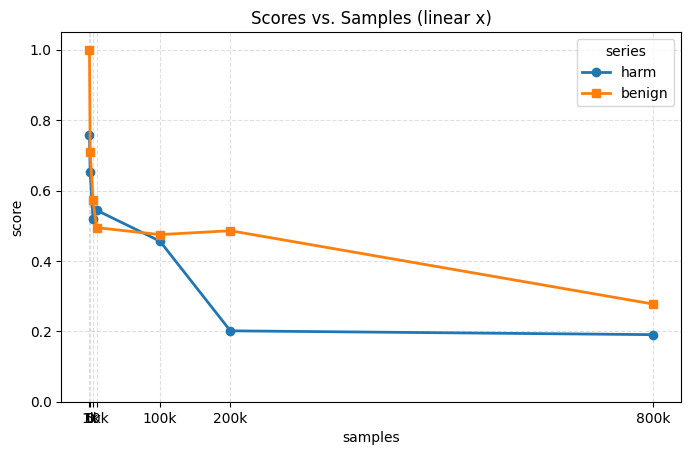

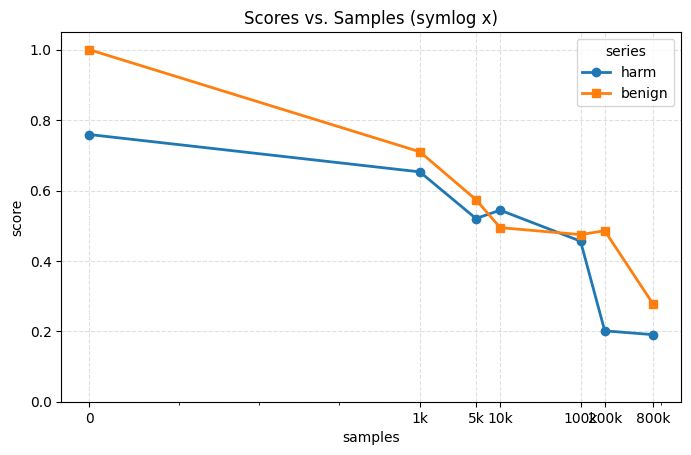

In [86]:
import matplotlib.pyplot as plt
import numpy as np

data = {
    'harm': {0: 0.7590367965367965,
             1000: 0.6529761904761905,
             5000: 0.5204545454545455,
             10000: 0.5442099567099568,
             100000: 0.4561688311688311,
             200000: 0.20140692640692642,
             800000: 0.19053030303030302},
    'benign': {0: 1.0,
               1000: 0.7101190476190476,
               5000: 0.574025974025974,
               10000: 0.49458874458874463,
               100000: 0.4747835497835498,
               200000: 0.48576839826839824,
               800000: 0.2774350649350649}
}

# Union of x-values across both series (sorted)
x_all = sorted({int(k) for series in data.values() for k in series.keys()})

def fmt_k(n: int) -> str:
    return f"{n//1000}k" if abs(n) >= 1000 else str(n)

def plot_series(ax, x_vals, series_dict, title_suffix="", use_symlog=False):
    markers = {'harm': 'o', 'benign': 's'}
    for name, series in series_dict.items():
        y = [series.get(x, np.nan) for x in x_vals]  # NaN to break line where missing
        ax.plot(x_vals, y, marker=markers.get(name, 'o'), linewidth=2, label=name)

    if use_symlog:
        # symlog keeps a small linear region around 0 so x=0 is allowed
        ax.set_xscale("symlog", linthresh=1)

    ax.set_ylim(0, 1.05)
    ax.set_xlabel("samples")
    ax.set_ylabel("score")
    ax.set_title(f"Scores vs. Samples {title_suffix}")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(title="series")
    ax.set_xticks(x_vals)
    ax.set_xticklabels([fmt_k(x) for x in x_vals])

# Figure 1: linear x-axis
fig1, ax1 = plt.subplots(figsize=(8, 4.8))
plot_series(ax1, x_all, data, title_suffix="(linear x)")

# Figure 2: log-like x-axis (symlog to keep x=0)
fig2, ax2 = plt.subplots(figsize=(8, 4.8))
plot_series(ax2, x_all, data, title_suffix="(symlog x)", use_symlog=True)

plt.show()

# --- Optional: strict log10 (drop x=0) ---
# x_pos = [x for x in x_all if x > 0]
# fig3, ax3 = plt.subplots(figsize=(8, 4.8))
# plot_series(ax3, x_pos, data, title_suffix="(log10 x)")
# ax3.set_xscale("log", base=10)
# plt.show()


score_threshold=1.0 remains num_samples=22


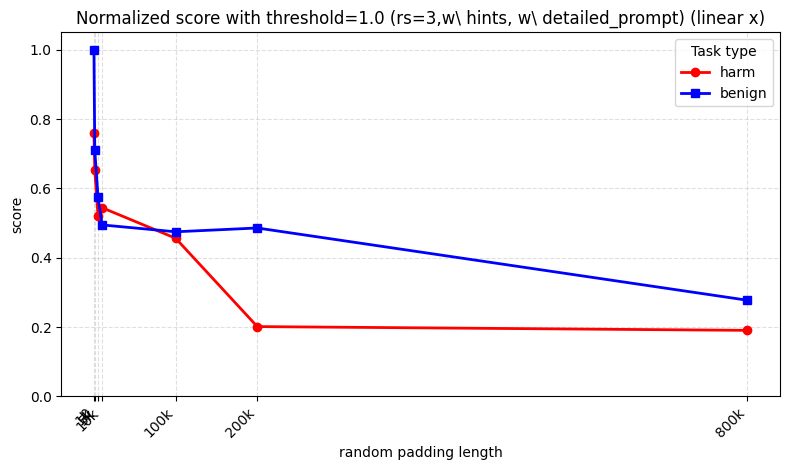

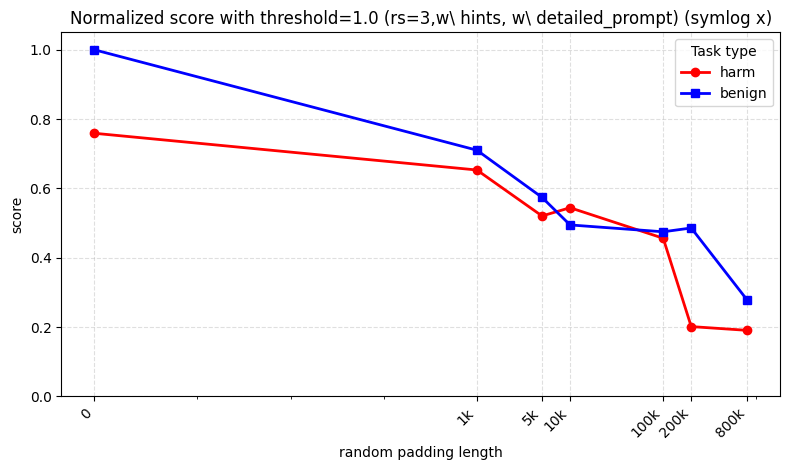

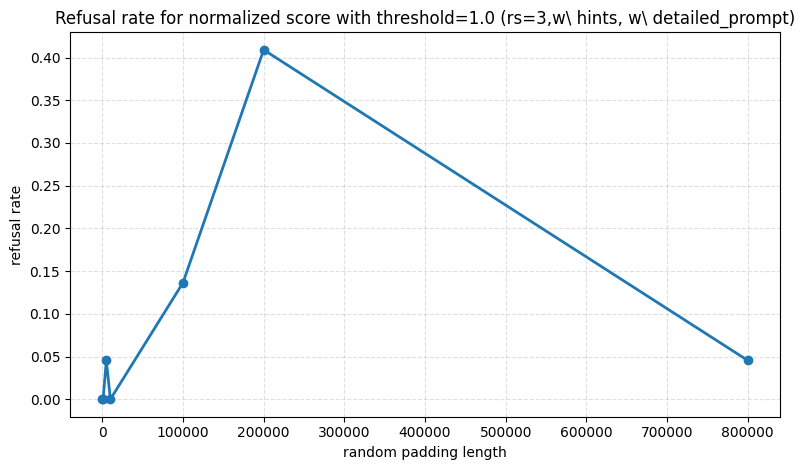

In [85]:
from turtle import color


score_threshold = 1.0
nss_filtered_scores, nss_refusal_rate = calculate_nss(padding2evals=padding2evals, score_threshold=score_threshold)
data = nss_filtered_scores

# Union of x-values across both series (sorted)
x_all = sorted({int(k) for series in data.values() for k in series.keys()})

def fmt_k(n: int) -> str:
    return f"{n//1000}k" if abs(n) >= 1000 else str(n)

def plot_series(ax, x_vals, series_dict, title_suffix="", use_symlog=False):
    markers = {'harm': 'o', 'benign': 's'}
    colors = {'harm': 'red', 'benign': 'blue'}
    for name, series in series_dict.items():
        y = [series.get(x, np.nan) for x in x_vals]  # NaN to break line where missing
        ax.plot(x_vals, y, marker=markers.get(name, 'o'), linewidth=2, label=name, color=colors.get(name, 'black'))

    if use_symlog:
        # symlog keeps a small linear region around 0 so x=0 is allowed
        ax.set_xscale("symlog", linthresh=1)

    ax.set_ylim(0, 1.05)
    ax.set_xlabel("random padding length")
    ax.set_ylabel("score")
    ax.set_title(f"Normalized score with threshold={score_threshold} (rs=3,w\\ hints, w\\ detailed_prompt) {title_suffix}")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(title="Task type")

    # Set ticks and rotate labels 45 degrees
    ax.set_xticks(x_vals)
    ax.set_xticklabels([fmt_k(x) for x in x_vals], rotation=45, ha="right")

# Figure 1: linear x-axis
fig1, ax1 = plt.subplots(figsize=(8, 4.8))
plot_series(ax1, x_all, data, title_suffix="(linear x)")
fig1.tight_layout()

# Figure 2: log-like x-axis (symlog to keep x=0)
fig2, ax2 = plt.subplots(figsize=(8, 4.8))
plot_series(ax2, x_all, data, title_suffix="(symlog x)", use_symlog=True)
fig2.tight_layout()

fig3, ax3 = plt.subplots(figsize=(8, 4.8))
ax3.plot(list(nss_refusal_rate.keys()), list(nss_refusal_rate.values()), marker='o', linewidth=2)
ax3.grid(True, linestyle="--", alpha=0.4)
ax3.set_xlabel("random padding length")
ax3.set_ylabel("refusal rate")
ax3.set_title(f"Refusal rate for normalized score with threshold={score_threshold} (rs=3,w\\ hints, w\\ detailed_prompt)")
fig3.tight_layout()


In [78]:
nss_refusal_rate

{0: 0.06818181818181818,
 1000: 0.06818181818181818,
 5000: 0.022727272727272728,
 10000: 0.0,
 100000: 0.20454545454545456,
 200000: 0.38636363636363635,
 800000: 0.1590909090909091}